# Diurnal Cycle

## Imports & Global Variables

In [93]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py
from scipy import signal
from pathlib import Path


ROLLING_WINDOW_DAYS = 31
REMOVE_DAILY_MEAN = True
ANOMALY_THRESHOLD = 3.0
MIN_COMPLETENESS = 0.95
BANDS_CPD = {"24-6 h": (1, 5), "5-1 h": (5, 24), "1 h-10 min": (24, 144), "10-2 min": (144, 721)}
MAX_GAP_S = 300

In [94]:
SUPPORTED = {".csv", ".npz", ".npy", ".h5", ".hdf5"}

ALIASES = {
    "time": (
        "timestamp_utc", "timestamp", "time",
        "time_s", "timestamp_us", "timestamp_ms",
        "yyyy-MM-dd HH:mm:ss"
    ),
    "magnitude": (
        "magnitude", "mag", "mag_nT", "magnitude_nT",
        "F", "total_field", "Mag (nT)", "F (nT)"
    ),
}

UNITS = {
    "timestamp_us": "us",
    "timestamp_ms": "ms",
    "time_s": "s",
}
SCALE = {"s": 1, "ms": 1e3, "us": 1e6, "ns": 1e9}


def _npy(path, stride):
    try:
        return np.load(path, mmap_mode="r")[::stride]
    except ValueError:
        a = np.load(path, allow_pickle=True)
        return a if a.ndim == 0 else a[::stride]


def _read_h5(path, stride):
    out = {}
    with h5py.File(path, "r") as f:
        def grab(name, obj):
            if isinstance(obj, h5py.Dataset) and obj.dtype.kind != "V":
                data = obj[::stride]
                if data.dtype.kind == "S":
                    data = np.char.decode(data, "utf-8")
                elif data.dtype.kind == "O":
                    data = np.array([x.decode() if isinstance(x, bytes) else x for x in data])
                out[name.split("/")[-1]] = data
        f.visititems(grab)
    return out


def _csv_header_row(path, max_lines=100):
    names = set(ALIASES["time"])
    with open(path, encoding="utf-8", errors="ignore") as f:
        for i, line in enumerate(f):
            if i >= max_lines:
                break
            if names & {c.strip() for c in line.split(",")}:
                return i
    return 0


def _read_raw(path, stride=1):
    """Read supported files into a dictionary of arrays."""
    path = Path(path)

    if path.is_dir():
        return {
            p.stem: _npy(p, stride)
            for p in path.glob("*.npy")
        }

    ext = path.suffix.lower()

    if ext == ".csv":
        header = _csv_header_row(path)
        df = pd.read_csv(
            path,
            skiprows=lambda i: (
                i < header or
                (i > header and (i - header) % stride != 0)
            )
        )
        return {c.strip(): df[c].to_numpy() for c in df.columns}

    if ext == ".npy":
        a = _npy(path, stride)
        if a.dtype.names:
            return {name: a[name] for name in a.dtype.names}
        if a.dtype == object and a.ndim == 0:
            return a.item()
        raise ValueError(
            f"Unrecognised .npy layout: shape {a.shape}, dtype {a.dtype}"
        )

    if ext == ".npz":
        with np.load(path, allow_pickle=True) as f:
            return {
                k: f[k][::stride] if f[k].ndim else f[k]
                for k in f.files
            }

    if ext in (".h5", ".hdf5"):
        return _read_h5(path, stride)

    raise ValueError(f"Unsupported file type: {ext}")


def _to_time(t, key, origin=None, source_tz=None):
    """Return a timezone-aware DatetimeIndex in UTC."""
    t = np.asarray(t)

    # Text or already-formatted timestamps
    if not np.issubdtype(t.dtype, np.number):
        ts = pd.DatetimeIndex(pd.to_datetime(t))

        if ts.tz is None:
            # Explicitly UTC-labelled columns are always interpreted as UTC.
            tz = "UTC" if key == "timestamp_utc" else source_tz
            if tz is None:
                raise ValueError(f"'{key}' has no timezone; pass source_tz='UTC' or 'Etc/GMT-10'")
            ts = ts.tz_localize(tz)

        return ts.tz_convert("UTC")

    if t.size == 0:
        return pd.DatetimeIndex([], tz="UTC")

    # Infer numeric timestamp units
    magnitude = np.nanmax(np.abs(t[:1000]))
    unit = UNITS.get(key) or (
        "ns" if magnitude > 1e17 else
        "us" if magnitude > 1e14 else
        "ms" if magnitude > 1e11 else
        "s"
    )

    # Unix epoch timestamps
    if origin is None and magnitude / SCALE[unit] > 946684800:
        return pd.to_datetime(t, unit=unit, utc=True)
        if origin is None:
            raise ValueError("Timestamps are relative (not Unix epoch); pass origin='YYYY-MM-DD HH:MM:SS'.")

    # Otherwise interpret as elapsed time from a specified/default origin.
    # Correct 32-bit counter wraparound when applicable.
    if np.issubdtype(t.dtype, np.integer) and np.all(t >= 0) and np.max(t) < 2**32:
        t = t.astype(np.int64)
        prev = np.r_[t[0], t[:-1]]
        t = t + 2**32 * np.cumsum((t < prev) & (prev > 0.9 * 2**32))
    else:
        t = t.astype(np.float64)

    start = pd.Timestamp(origin or "2000-01-01")
    if start.tzinfo is None:
        start = start.tz_localize(source_tz)
    start = start.tz_convert("UTC")

    elapsed = pd.to_timedelta(t - t[0], unit=unit)
    return pd.DatetimeIndex(start + elapsed)


def load_magnitude_data(
    filename,
    stride=1,
    origin=None,
    source_tz=None,
    calibration=1.0,
):
    """
    Load timestamps and the existing magnitude field.

    Returns a DataFrame with:
        time       - timezone-aware UTC timestamps
        magnitude  - stored magnitude values, optionally scaled
    """
    if stride < 1:
        raise ValueError("stride must be >= 1")

    raw = _read_raw(Path(filename), stride)

    time_key = next(
        (key for key in ALIASES["time"] if key in raw), None
    )
    mag_key = next(
        (key for key in ALIASES["magnitude"] if key in raw), None
    )

    if time_key is None:
        raise KeyError(
            f"No timestamp field found. Available fields: {list(raw)}"
        )

    if mag_key is None:
        raise KeyError(
            "No magnitude field found. "
            f"Available fields: {list(raw)}. "
            "Add the actual magnitude column/dataset name to "
            "ALIASES['magnitude']."
        )

    time = _to_time(
        raw[time_key],
        time_key,
        origin=origin,
        source_tz=source_tz,
    )
    magnitude = np.asarray(raw[mag_key], dtype=np.float64) * calibration

    if len(time) != len(magnitude):
        raise ValueError(
            f"Timestamp and magnitude lengths differ: "
            f"{len(time)} vs {len(magnitude)}"
        )

    return (
        pd.DataFrame({"time": time, "magnitude": magnitude})
        .sort_values("time")
        .reset_index(drop=True)
    )

## Time Based Analysis

In [95]:
def split_into_days(data, remove_mean=True, day_offset_h=0.0):
    """
    Split timestamped magnitude data into UTC daily curves.

    Parameters
    ----------
    data : pandas.DataFrame
        Must contain 'time' and 'magnitude' columns.
        Timestamps must be timezone-aware.
    remove_mean : bool
        If True, subtract each day's mean from its valid samples.

    Returns
    -------
    daily_curves : DataFrame
        Daily curves, optionally mean-subtracted.
        Rows are dates; columns are minutes 0 to 1439.
    raw_daily_curves : DataFrame
        Original magnitude curves, without mean subtraction.
    daily_quality : DataFrame
        Data-quality information for each day.
    """

    # 1. Validate inputs
    required = {"time", "magnitude"}
    if not required.issubset(data.columns):
        raise ValueError(
            f"Data must contain columns {required}"
        )

    df = data[["time", "magnitude"]].copy()

    # 2. Ensure timestamps are timezone-aware and convert to UTC
    df["time"] = pd.to_datetime(df["time"])

    if df["time"].dt.tz is None:
        raise ValueError(
            "Timestamps must be timezone-aware. "
            "Load or localise them to UTC first."
        )

    df["time"] = df["time"].dt.tz_convert("UTC")

    # 3. Validate and prepare magnitude values
    df["magnitude"] = pd.to_numeric(
        df["magnitude"], errors="coerce"
    )
    df = df.dropna(subset=["time"])
    df = df.sort_values("time")

    # Ignore infinite values, treating them as missing measurements
    df.loc[~np.isfinite(df["magnitude"]), "magnitude"] = np.nan

    if df.empty:
        raise ValueError("No timestamped data available.")

    # 4. Assign each observation to a UTC date and minute
    shifted = df["time"] + pd.Timedelta(hours=day_offset_h)
    df["date"] = shifted.dt.normalize()
    df["minute"] = shifted.dt.hour * 60 + shifted.dt.minute

    # 5. Count observations and valid measurements per minute.
    # If multiple observations occur within one minute, average them.
    grouped = df.groupby(["date", "minute"])["magnitude"]

    minute_means = grouped.mean().unstack("minute")
    observation_counts = grouped.size().unstack("minute")
    
    # 6. Create a complete 1440-minute grid for every calendar day,
    # including entirely missing days between the first and last date.
    all_dates = pd.date_range(
        df["date"].min(),
        df["date"].max(),
        freq="D",
        tz="UTC"
    )

    minutes = range(1440)

    raw_daily_curves = minute_means.reindex(
        index=all_dates,
        columns=minutes
    )
    observation_counts = observation_counts.reindex(
        index=all_dates,
        columns=minutes,
        fill_value=0
    ).fillna(0)

    raw_daily_curves.index.name = "date"
    raw_daily_curves.columns.name = "minute"

    # 7. Calculate daily means and optionally subtract them
    daily_means = raw_daily_curves.mean(axis=1)

    if remove_mean:
        daily_curves = raw_daily_curves.sub(
            daily_means, axis=0
        )
    else:
        daily_curves = raw_daily_curves.copy()

    # 8. Calculate daily quality statistics
    valid_minutes = raw_daily_curves.notna().sum(axis=1)

    daily_quality = pd.DataFrame(index=all_dates)
    daily_quality.index.name = "date"
    daily_quality["valid_minutes"] = valid_minutes
    daily_quality["missing_minutes"] = 1440 - valid_minutes
    daily_quality["completeness"] = valid_minutes / 1440
    daily_quality["daily_mean"] = daily_means

    # Count extra observations within already occupied minutes
    daily_quality["extra_samples"] = (
        observation_counts.clip(lower=1) - 1
    ).where(observation_counts > 0, 0).sum(axis=1).astype(int)

    # Flag days with no valid magnitude observations
    daily_quality["empty_day"] = valid_minutes == 0

    return daily_curves, raw_daily_curves, daily_quality

In [96]:
def build_rolling_reference(
    daily_curves,
    daily_quality,
    window_days=31,
    min_completeness=0.95,
    min_reference_days=7,
    min_samples_per_minute=3,
):
    """
    Build a rolling median reference curve for each UTC day.

    Parameters
    ----------
    daily_curves : DataFrame
        Daily curves from Cell 2, optionally mean-subtracted.
    daily_quality : DataFrame
        Quality information from Cell 2.
    window_days : int
        Width of the centred rolling window in calendar days.
    min_completeness : float
        Minimum daily completeness required for a reference day.
    min_reference_days : int
        Minimum number of eligible neighbouring days required.
    min_samples_per_minute : int
        Minimum valid reference measurements needed at each minute.

    Returns
    -------
    reference_curves : DataFrame
        Expected median curve for each target day.
    reference_counts : DataFrame
        Number of valid reference measurements contributing
        to each minute of each reference curve.
    """

    if window_days < 1:
        raise ValueError("window_days must be >= 1")

    if window_days % 2 == 0:
        raise ValueError("window_days must be odd, e.g. 31")

    if min_reference_days < 1:
        raise ValueError("min_reference_days must be >= 1")

    if not 0 <= min_completeness <= 1:
        raise ValueError("min_completeness must be between 0 and 1")

    # Ensure quality information aligns with the daily curves
    quality = daily_quality.reindex(daily_curves.index)

    # Decide which days are eligible to contribute to references
    eligible = (
        (quality["completeness"] >= min_completeness)
        & (~quality["empty_day"])
    )

    half_window = window_days // 2

    # Prepare output tables
    reference_curves = pd.DataFrame(
        np.nan,
        index=daily_curves.index,
        columns=daily_curves.columns,
    )

    reference_counts = pd.DataFrame(
        0,
        index=daily_curves.index,
        columns=daily_curves.columns,
        dtype=int,
    )

    # Build a separate reference for each target day
    for target_date in daily_curves.index:

        start_date = target_date - pd.Timedelta(days=half_window)
        end_date = target_date + pd.Timedelta(days=half_window)

        # Select neighbouring days inside the rolling window
        in_window = (
            (daily_curves.index >= start_date)
            & (daily_curves.index <= end_date)
        )

        candidate_dates = daily_curves.index[
            in_window & eligible.to_numpy()
        ]

        # Exclude the target day from its own reference
        candidate_dates = candidate_dates[
            candidate_dates != target_date
        ]

        if len(candidate_dates) < min_reference_days:
            continue

        neighbours = daily_curves.loc[candidate_dates]

        # Count valid contributors separately for each minute
        counts = neighbours.notna().sum(axis=0)

        # Median across neighbouring days, ignoring missing values
        median_curve = neighbours.median(axis=0)

        # Require enough valid observations at each minute
        median_curve[counts < min_samples_per_minute] = np.nan

        reference_curves.loc[target_date] = median_curve
        reference_counts.loc[target_date] = counts

    return reference_curves, reference_counts

In [97]:
def score_daily_anomalies(
    daily_curves,
    reference_curves,
    min_valid_minutes=1000,
):
    """
    Measure how much each daily curve differs from its reference.

    Returns a DataFrame containing daily error metrics and a
    robust anomaly score based on RMSE.
    """

    results = []

    for date in daily_curves.index:
        observed = daily_curves.loc[date].to_numpy(dtype=float)
        reference = reference_curves.loc[date].to_numpy(dtype=float)

        # Compare only minutes where both curves have valid data
        valid = np.isfinite(observed) & np.isfinite(reference)
        residuals = observed[valid] - reference[valid]

        if valid.sum() < min_valid_minutes:
            results.append({
                "date": date,
                "valid_minutes": int(valid.sum()),
                "rmse": np.nan,
                "mae": np.nan,
                "max_abs_deviation": np.nan,
                "residual_variability": np.nan,
            })
            continue

        results.append({
            "date": date,
            "valid_minutes": int(valid.sum()),
            "rmse": float(np.sqrt(np.mean(residuals**2))),
            "mae": float(np.mean(np.abs(residuals))),
            "max_abs_deviation": float(np.max(np.abs(residuals))),
            "residual_variability": float(np.std(residuals)),
        })

    scores = pd.DataFrame(results).set_index("date")

    # Robustly compare each day's RMSE against the dataset's RMSE values.
    # MAD is less sensitive to extreme scores than standard deviation.
    valid_rmse = scores["rmse"].dropna()
    if len(valid_rmse) < 15:
        print(f"Warning: only {len(valid_rmse)} scored days; robust scores will be unreliable.")

    if len(valid_rmse) >= 2:
        median_rmse = valid_rmse.median()
        mad = (valid_rmse - median_rmse).abs().median()

        if mad > 0:
            scores["robust_score"] = (
                scores["rmse"] - median_rmse
            ) / (1.4826 * mad)
        else:
            # Fallback when the median absolute deviation is zero
            spread = valid_rmse.std()
            scores["robust_score"] = (scores["rmse"] - median_rmse) / spread if spread > 0 else np.nan
    else:
        scores["robust_score"] = np.nan

    return scores

In [98]:
def classify_daily_anomalies(
    anomaly_scores,
    daily_quality,
    robust_threshold=3.0,
    min_completeness=0.95,
):
    """
    Classify days as normal, abnormal, or insufficient data.

    A day is flagged as abnormal when its robust score exceeds
    the selected threshold. Days with insufficient data or no
    usable score are not classified as normal.
    """

    results = anomaly_scores.copy()
    quality = daily_quality.reindex(results.index)

    # Start with every day unclassified
    results["classification"] = "insufficient data"

    # Days must have enough data and a valid anomaly score
    usable = (
        (quality["completeness"] >= min_completeness)
        & (~quality["empty_day"])
        & results["robust_score"].notna()
    )

    # Classify usable days
    results.loc[usable, "classification"] = "normal"

    abnormal = usable & (
        results["robust_score"] >= robust_threshold
    )

    results.loc[abnormal, "classification"] = "abnormal"

    return results

In [99]:
def build_normal_daily_curve(
    daily_curves,
    classified_days,
    min_normal_days=5,
):
    """
    Calculate a representative daily curve from classified normal days.

    Returns
    -------
    normal_curve : Series
        Median normal-day value at each minute.
    normal_spread : Series
        Median absolute deviation from the normal curve at each minute.
    normal_dates : DatetimeIndex
        Dates included in the normal-day reference.
    """

    normal_dates = classified_days.index[
        classified_days["classification"] == "normal"
    ]

    if len(normal_dates) < min_normal_days:
        raise ValueError(
            f"Only {len(normal_dates)} normal days available. "
            f"At least {min_normal_days} required."
        )

    normal_data = daily_curves.loc[normal_dates]

    normal_curve = normal_data.median(axis=0)

    # Typical minute-by-minute spread among normal days
    normal_spread = normal_data.sub(normal_curve, axis=1).abs().median(axis=0)

    return normal_curve, normal_spread, normal_dates

In [100]:
def analyse_file(filename, source_tz=None, **kwargs):
    data = load_magnitude_data(filename, source_tz=source_tz)
    return analyse_dataframe(data, **kwargs)

def summarise_days(res):
    counts = res["classified_days"]["classification"].value_counts()
    print(f"Total days: {len(res['daily_curves'])}")
    for label in ("normal", "abnormal", "insufficient data"):
        print(f"{label.capitalize()} days: {counts.get(label, 0)}")

def plot_normal_curve(res, title="Expected normal diurnal pattern", xlabel="Time of day (UTC)",
                      show_normal_days=True, show_abnormal_days=True):
    daily = res["daily_curves"]
    cls = res["classified_days"]["classification"]
    minutes = daily.columns.to_numpy()
    fig, ax = plt.subplots(figsize=(14, 8))
    if show_normal_days:
        for date in res["normal_dates"]:
            ax.plot(minutes, daily.loc[date].to_numpy(), color="steelblue", alpha=0.15, linewidth=0.8)
    if show_abnormal_days:
        for i, date in enumerate(cls.index[cls == "abnormal"]):
            ax.plot(minutes, daily.loc[date].to_numpy(), color="crimson", alpha=0.7, linewidth=1.0,
                    label="Abnormal days" if i == 0 else None)
    curve, spread = res["normal_curve"], res["normal_spread"]
    ax.plot(minutes, curve.to_numpy(), color="black", linewidth=2.5, label="Median normal-day curve")
    ax.fill_between(minutes, (curve - spread).to_numpy(), (curve + spread).to_numpy(),
                    color="orange", alpha=0.25, label="Median absolute deviation band")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Magnitude variation (nT)")
    ax.set_xticks(np.arange(0, 1441, 120), [f"{h:02d}:00" for h in range(0, 25, 2)])
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    return fig

In [101]:
def analyse_dataframe(data, remove_mean=True, window_days=31, min_completeness=0.95,
                      min_reference_days=7, robust_threshold=3.0,
                      min_valid_minutes=1000, min_normal_days=5):
    daily_curves, raw_daily_curves, daily_quality = split_into_days(data, remove_mean=remove_mean)
    reference_curves, reference_counts = build_rolling_reference(
        daily_curves, daily_quality, window_days=window_days,
        min_completeness=min_completeness, min_reference_days=min_reference_days)
    anomaly_scores = score_daily_anomalies(daily_curves, reference_curves,
                                           min_valid_minutes=min_valid_minutes)
    classified_days = classify_daily_anomalies(anomaly_scores, daily_quality,
                                               robust_threshold=robust_threshold,
                                               min_completeness=min_completeness)
    normal_curve, normal_spread, normal_dates = build_normal_daily_curve(
        daily_curves, classified_days, min_normal_days=min_normal_days)
    return {"data": data, "daily_curves": daily_curves, "raw_daily_curves": raw_daily_curves,
            "daily_quality": daily_quality, "reference_curves": reference_curves,
            "reference_counts": reference_counts, "anomaly_scores": anomaly_scores,
            "classified_days": classified_days, "normal_curve": normal_curve,
            "normal_spread": normal_spread, "normal_dates": normal_dates}

## Fourier (Abandoned probably)

In [102]:
def regular_grid(data, column="magnitude", dt_s=1.0, max_gap_s=MAX_GAP_S):
    """Mean-bin onto a regular time grid; linearly fill gaps up to max_gap_s, leave longer gaps NaN."""
    s = data.set_index("time")[column].astype(float).sort_index()
    s.index = s.index.tz_convert("UTC")
    grid = s.resample(pd.Timedelta(seconds=dt_s)).mean()
    is_nan = grid.isna()
    run_id = (is_nan != is_nan.shift()).cumsum()
    gap_len = is_nan.groupby(run_id).transform("sum")      # length of each NaN run
    filled = grid.interpolate(limit_area="inside")
    filled[gap_len > max_gap_s / dt_s] = np.nan
    return filled

In [103]:
def finite_runs(valid, min_len=1):
    """(start, stop) index pairs of consecutive True runs at least min_len long."""
    edges = np.flatnonzero(np.diff(np.r_[False, valid, False].astype(int)))
    return [(a, b) for a, b in zip(edges[::2], edges[1::2]) if b - a >= min_len]

In [104]:
def segment_series(data, column="magnitude", dt_s=1.0, max_gap_s=MAX_GAP_S, min_len=64):
    """Gap-free, evenly sampled segments as [(start_time, values), ...]."""
    g = regular_grid(data, column, dt_s, max_gap_s)
    v = g.to_numpy()
    return [(g.index[a], v[a:b]) for a, b in finite_runs(~np.isnan(v), min_len)]

In [105]:
def welch_psd(segments, dt_s, nperseg_s=3600, overlap=0.5, detrend="linear"):
    """Welch PSD (nT^2/Hz) averaged over gap-free segments, weighted by number of windows."""
    nperseg = int(nperseg_s / dt_s)
    noverlap = int(nperseg * overlap)
    step = nperseg - noverlap
    total, n_total = 0.0, 0
    for _, x in segments:
        if len(x) < nperseg:
            continue
        f, p = signal.welch(x, fs=1 / dt_s, window="hann", nperseg=nperseg,
                            noverlap=noverlap, detrend=detrend)
        n_win = 1 + (len(x) - nperseg) // step
        total = total + p * n_win
        n_total += n_win
    if n_total == 0:
        raise ValueError("No segment is long enough for nperseg_s; shorten it or raise max_gap_s.")
    out = pd.DataFrame({"freq_hz": f[1:], "psd": (total / n_total)[1:]})
    out["period_s"] = 1 / out["freq_hz"]
    out.attrs["n_windows"] = n_total
    return out

In [106]:
def find_spectral_lines(psd, prominence_db=6.0, min_period_s=None, max_period_s=None):
    """Narrow peaks standing out of the PSD background (e.g. a radio duty-cycle line)."""
    y = 10 * np.log10(psd["psd"].to_numpy())
    idx, props = signal.find_peaks(y, prominence=prominence_db)
    out = psd.iloc[idx].copy()
    out["prominence_db"] = props["prominences"]
    if min_period_s is not None:
        out = out[out["period_s"] >= min_period_s]
    if max_period_s is not None:
        out = out[out["period_s"] <= max_period_s]
    return out.sort_values("prominence_db", ascending=False).reset_index(drop=True)

In [107]:
def compute_spectrogram(segments, dt_s, window_s=1800, overlap=0.5):
    """Time-frequency power (nT^2/Hz) per gap-free segment: [(times, freqs, Sxx), ...]."""
    nperseg = int(window_s / dt_s)
    out = []
    for start, x in segments:
        if len(x) < nperseg:
            continue
        f, t, S = signal.spectrogram(x, fs=1 / dt_s, window="hann", nperseg=nperseg,
                                     noverlap=int(nperseg * overlap), detrend="linear")
        out.append((start + pd.to_timedelta(t, unit="s"), f, S))
    if not out:
        raise ValueError("No segment is long enough for window_s.")
    return out

In [108]:
def harmonic_spectrum(curve, n_harmonics=8):
    """Fourier-series amplitude (nT) and first-maximum time (hours after day start) of a 24 h curve."""
    x = pd.Series(np.asarray(curve, float)).interpolate(limit_direction="both").to_numpy()
    N = len(x)
    x = x - np.linspace(x[0], x[-1], N)            # force matching endpoints (periodic)
    k = np.arange(1, n_harmonics + 1)
    coef = 2 * np.fft.rfft(x)[k] / N
    return pd.DataFrame({
        "period_h": 24 / k,
        "amplitude_nT": np.abs(coef),
        "peak_h": ((-np.angle(coef) / (2 * np.pi * k)) * 24) % (24 / k),
        "coef": coef,
    }, index=k)

In [109]:
def bootstrap_harmonics(daily_curves, normal_dates, n_harmonics=6, n_boot=500, seed=0):
    """Resample normal days with replacement: amplitude spread and circular peak-time spread."""
    rng = np.random.default_rng(seed)
    days = daily_curves.loc[normal_dates].to_numpy(float)
    coefs = np.array([
        harmonic_spectrum(np.nanmedian(days[rng.integers(0, len(days), len(days))], axis=0),
                          n_harmonics)["coef"].to_numpy()
        for _ in range(n_boot)
    ])                                                       # (n_boot, n_harmonics)
    k = np.arange(1, n_harmonics + 1)
    amp = np.abs(coefs)
    z = np.mean(np.exp(1j * np.angle(coefs)), axis=0)        # circular mean of phase
    return pd.DataFrame({
        "period_h": 24 / k,
        "amp_median": np.median(amp, axis=0),
        "amp_lo": np.percentile(amp, 2.5, axis=0),
        "amp_hi": np.percentile(amp, 97.5, axis=0),
        "peak_h": ((-np.angle(z) / (2 * np.pi * k)) * 24) % (24 / k),
        "peak_sd_h": np.sqrt(-2 * np.log(np.abs(z))) / (2 * np.pi * k) * 24,
    }, index=k)

In [110]:
def daily_residual_spectra(daily_curves, reference_curves, daily_quality, min_completeness=0.95):
    """Periodogram of each usable day's residual from its reference (1-minute grid).
    Returns (spectra, df_hz): rows = dates, columns = cycles/day, values = nT^2/Hz."""
    rows = {}
    for date in daily_curves.index:
        if daily_quality.loc[date, "completeness"] < min_completeness:
            continue
        r = daily_curves.loc[date] - reference_curves.loc[date]
        if r.isna().all():
            continue
        r = r.interpolate(limit_direction="both").to_numpy()
        f, p = signal.periodogram(r, fs=1 / 60, window="hann", detrend="linear")
        rows[date] = p
    if not rows:
        raise ValueError("No usable days.")
    cpd = np.rint(f * 86400).astype(int)
    return pd.DataFrame(rows, index=cpd).T, f[1] - f[0]

In [111]:
def band_rms(spectra, df_hz, bands=BANDS_CPD):
    """RMS (nT) of each day's residual within each period band."""
    cpd = spectra.columns.to_numpy()
    return pd.DataFrame({
        name: np.sqrt(spectra.loc[:, (cpd >= lo) & (cpd < hi)].sum(axis=1) * df_hz)
        for name, (lo, hi) in bands.items()
    })

In [112]:
def band_anomaly_table(rms, classified_days):
    """Robust z-score (vs normal days) of each day's band RMS, beside the classifier's label."""
    cls = classified_days["classification"].reindex(rms.index)
    normal = rms[cls == "normal"]
    med = normal.median()
    mad = (normal - med).abs().median() * 1.4826
    z = (rms - med) / mad.replace(0, np.nan)
    return pd.concat([cls.rename("class"), rms.add_suffix(" rms"), z.add_suffix(" z")], axis=1)

In [113]:
def coherence_between(a, b, column="magnitude", dt_s=60.0, nperseg_s=7200,
                      overlap=0.5, max_gap_s=MAX_GAP_S):
    """Magnitude-squared coherence vs frequency (e.g. unit vs BOM) over their gap-free overlap."""
    both = pd.concat([regular_grid(a, column, dt_s, max_gap_s),
                      regular_grid(b, column, dt_s, max_gap_s)],
                     axis=1, join="inner", keys=["a", "b"])
    xa, xb = both["a"].to_numpy(), both["b"].to_numpy()
    nperseg = int(nperseg_s / dt_s)
    noverlap = int(nperseg * overlap)
    step = nperseg - noverlap
    kw = dict(fs=1 / dt_s, window="hann", nperseg=nperseg, noverlap=noverlap, detrend="linear")
    pxx = pyy = pxy = 0.0
    n_total = 0
    for i0, i1 in finite_runs(both.notna().all(axis=1).to_numpy(), min_len=nperseg):
        f, p1 = signal.welch(xa[i0:i1], **kw)
        _, p2 = signal.welch(xb[i0:i1], **kw)
        _, p12 = signal.csd(xa[i0:i1], xb[i0:i1], **kw)
        n_win = 1 + (i1 - i0 - nperseg) // step
        pxx, pyy, pxy, n_total = pxx + p1 * n_win, pyy + p2 * n_win, pxy + p12 * n_win, n_total + n_win
    if n_total == 0:
        raise ValueError("No overlapping gap-free run is long enough for nperseg_s.")
    coh = np.abs(pxy / n_total) ** 2 / ((pxx / n_total) * (pyy / n_total))
    out = pd.DataFrame({"freq_hz": f[1:], "coherence": coh[1:]})
    out["period_s"] = 1 / out["freq_hz"]
    out.attrs["n_windows"] = n_total
    return out

In [114]:
def plot_psd(psds, labels=None, mark_periods_s=(86400, 43200), title="Power spectral density"):
    fig, ax = plt.subplots(figsize=(10, 6))
    for i, p in enumerate(psds):
        ax.loglog(p["freq_hz"], p["psd"], lw=1, label=labels[i] if labels else None)
    for P in mark_periods_s:
        ax.axvline(1 / P, color="grey", ls=":", lw=0.8)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("PSD (nT$^2$/Hz)")
    ax.set_title(title)
    ax.grid(alpha=0.3, which="both")
    if labels:
        ax.legend()
    fig.tight_layout()
    return fig

In [131]:
# def plot_harmonics(harm, boot=None, title="Normal-day curve: Fourier harmonics"):
#     amp = harm["amplitude_nT"].to_numpy()
#     x = np.arange(len(harm))
#     fig, ax = plt.subplots(figsize=(8, 5))
#     ax.bar(x, amp, color="steelblue")
#     if boot is not None:
#         err = [np.clip(amp - boot["amp_lo"].to_numpy(), 0, None),
#                np.clip(boot["amp_hi"].to_numpy() - amp, 0, None)]
#         ax.errorbar(x, amp, yerr=err, fmt="none", ecolor="black", capsize=3)
#     for xi, (a, t) in enumerate(zip(amp, harm["peak_h"])):
#         ax.text(xi, a, f"peak {t:.1f} h", ha="center", va="bottom", fontsize=8)
#     ax.set_xticks(x, [f"{p:.1f} h" for p in harm["period_h"]])
#     ax.set_xlabel("Period")
#     ax.set_ylabel("Amplitude (nT)")
#     ax.set_title(title)
#     fig.tight_layout()
#     return fig


def plot_harmonics(harm, boot=None, title="Harmonic spectrum"):
    import numpy as np
    import matplotlib.pyplot as plt

    harm = harm.reset_index(drop=True).copy()
    fig, ax = plt.subplots(figsize=(8, 5))

    x = np.arange(len(harm))
    amp = harm["amplitude_nT"].to_numpy()

    ax.bar(x, amp, color="steelblue")

    if boot is not None and len(boot) > 0:
        # Match bootstrap intervals to the corresponding periods.
        aligned = harm[["period_h"]].merge(
            boot[["period_h", "amp_lo", "amp_hi"]],
            on="period_h",
            how="left",
            sort=False
        )

        lo = aligned["amp_lo"].to_numpy()
        hi = aligned["amp_hi"].to_numpy()

        # Only plot intervals for harmonics with available bootstrap results.
        valid = np.isfinite(lo) & np.isfinite(hi)

        lower_err = np.maximum(amp[valid] - lo[valid], 0)
        upper_err = np.maximum(hi[valid] - amp[valid], 0)

        ax.errorbar(
            x[valid],
            amp[valid],
            yerr=np.vstack([lower_err, upper_err]),
            fmt="none",
            ecolor="black",
            capsize=3
        )

    ax.set_xticks(x)
    ax.set_xticklabels(
        [f"{p:g}" for p in harm["period_h"]]
    )
    ax.set_xlabel("Period (hours)")
    ax.set_ylabel("Amplitude (nT)")
    ax.set_title(title)
    fig.tight_layout()

    return fig


In [116]:
def plot_band_heatmap(table, vmax=6):
    zcols = [c for c in table.columns if c.endswith(" z")]
    z = table[zcols].to_numpy(float).T
    fig, ax = plt.subplots(figsize=(max(8, 0.35 * len(table)), 3 + 0.6 * len(zcols)))
    im = ax.imshow(z, aspect="auto", cmap="coolwarm", vmin=-vmax, vmax=vmax)
    ax.set_yticks(range(len(zcols)), [c[:-2] for c in zcols])
    labels = [d.strftime("%m-%d") + ("*" if c == "abnormal" else "")
              for d, c in zip(table.index, table["class"])]
    ax.set_xticks(range(len(table)), labels, rotation=90)
    fig.colorbar(im, ax=ax, label="robust z (vs normal days)")
    ax.set_title("Band power vs normal days (* = flagged abnormal)")
    fig.tight_layout()
    return fig

In [117]:
def plot_spectrogram(spec, title="Spectrogram", db_range=50):
    db = [10 * np.log10(S[1:] + 1e-12) for _, _, S in spec]
    vmax = np.percentile(np.concatenate([d.ravel() for d in db]), 99)
    fig, ax = plt.subplots(figsize=(14, 5))
    for (times, f, _), d in zip(spec, db):
        t = times.tz_convert("UTC").tz_localize(None).to_numpy()
        m = ax.pcolormesh(t, f[1:], d, shading="nearest", vmin=vmax - db_range, vmax=vmax)
    ax.set_yscale("log")
    ax.set_xlabel("Time (UTC)")
    ax.set_ylabel("Frequency (Hz)")
    ax.set_title(title)
    fig.colorbar(m, ax=ax, label="dB re 1 nT$^2$/Hz")
    fig.autofmt_xdate()
    return fig

In [118]:
def plot_coherence(coh, title="Coherence between unit and reference"):
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.semilogx(coh["period_s"] / 3600, coh["coherence"], lw=1)
    ax.invert_xaxis()
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("Period (hours)")
    ax.set_ylabel("Magnitude-squared coherence")
    ax.set_title(f"{title} ({coh.attrs.get('n_windows', '?')} averaged windows)")
    ax.grid(alpha=0.3, which="both")
    fig.tight_layout()
    return fig

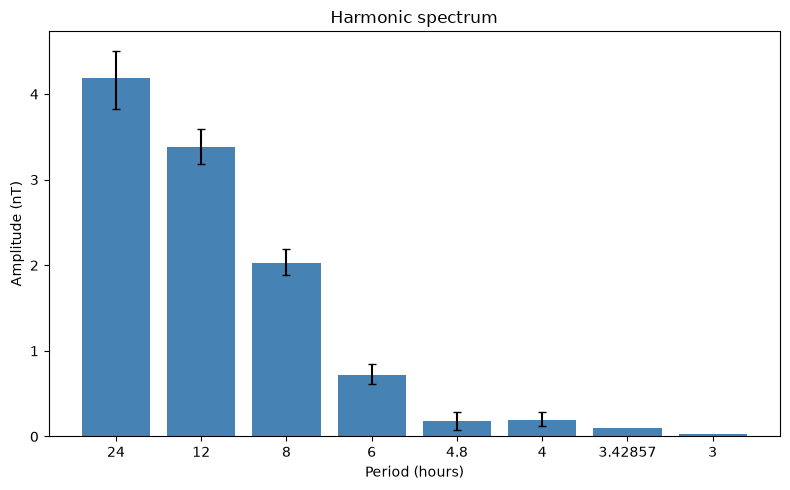

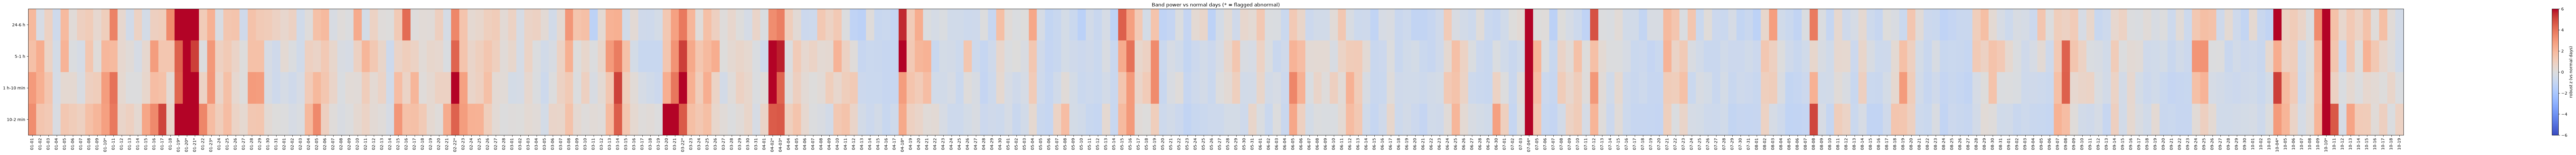

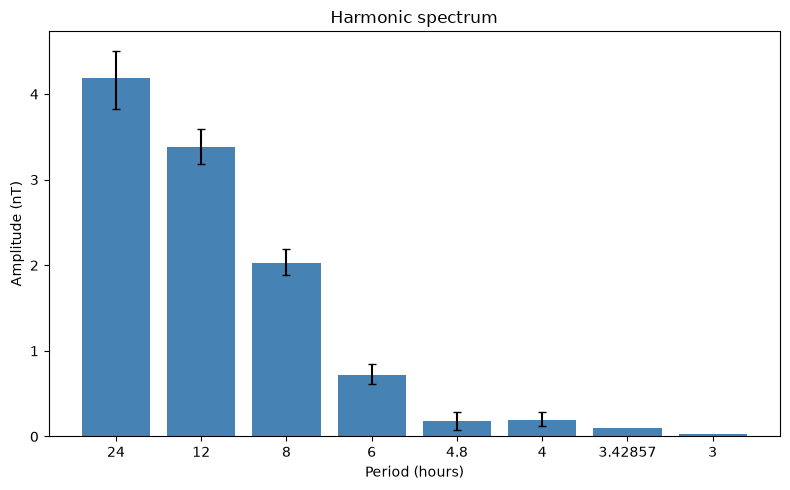

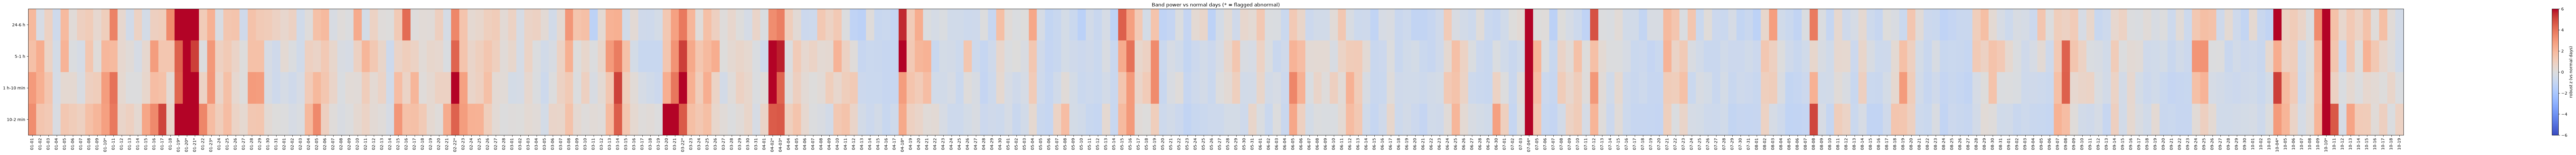

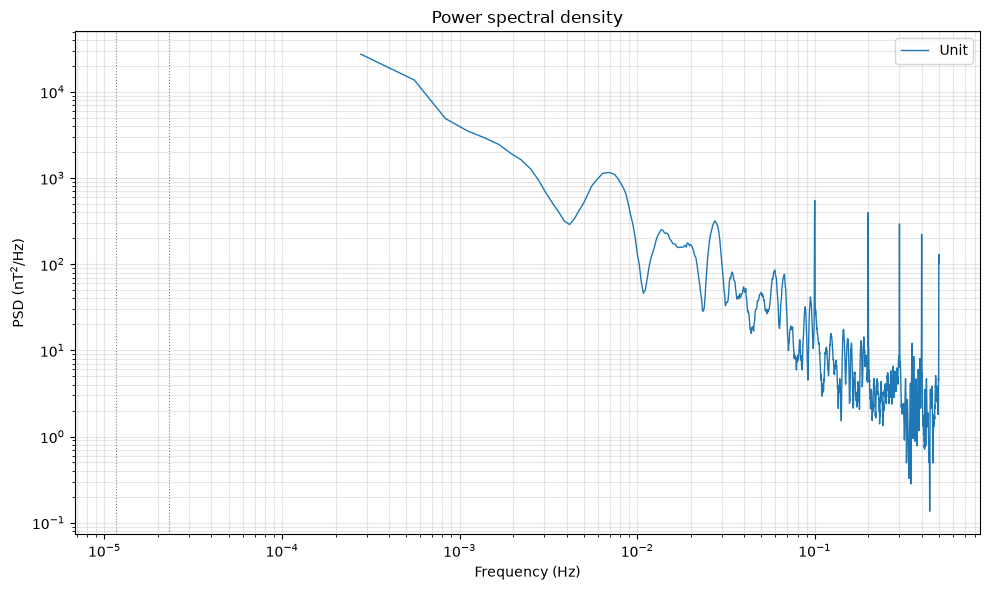

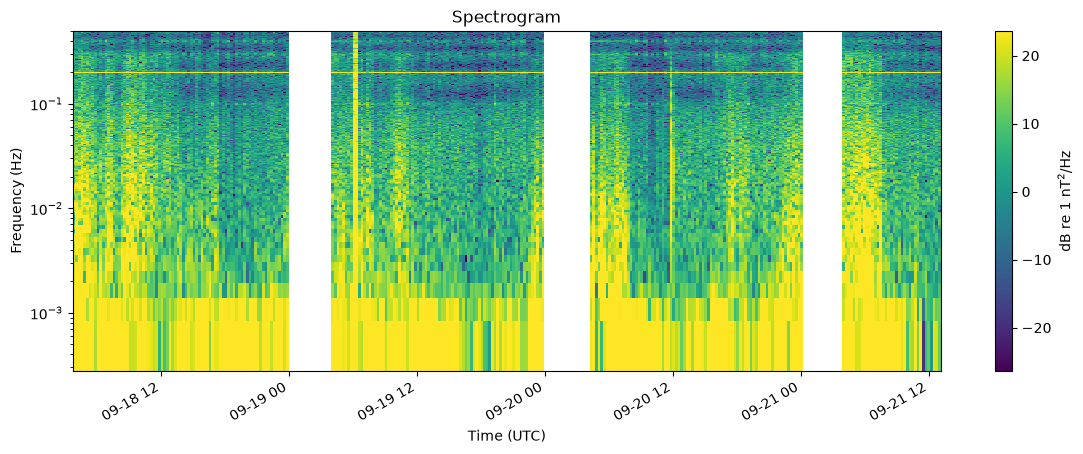

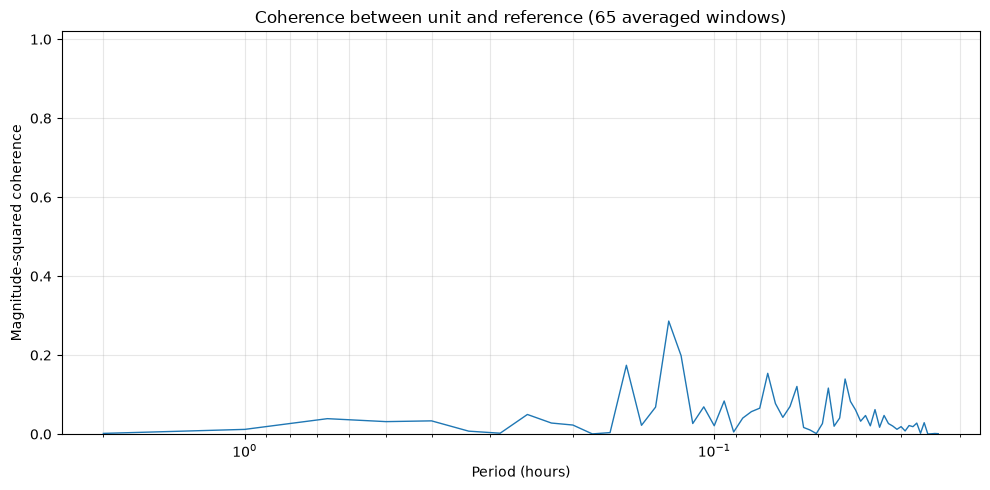

In [135]:
# Normal-day Fourier series and which bands drive abnormal days
res = analyse_file('data/long-bom.csv', source_tz='UTC')

harm = harmonic_spectrum(res["normal_curve"])
boot = bootstrap_harmonics(res["daily_curves"], res["normal_dates"])
fig = plot_harmonics(harm, boot)

spectra, df_hz = daily_residual_spectra(
    res["daily_curves"],
    res["reference_curves"],
    res["daily_quality"]
)
table = band_anomaly_table(
    band_rms(spectra, df_hz),
    res["classified_days"]
)
fig = plot_band_heatmap(table)

# ---


# ===== Specify your files here =====
bom_file = "data/long-bom.csv"
unit_file = "data/creek-sep18-22.npz"  # Change to your file
source_tz = "UTC"

import pandas as pd
import matplotlib.pyplot as plt

# Load and analyse BOM data
bom_df = load_magnitude_data(bom_file, source_tz=source_tz)
res = analyse_dataframe(bom_df)

# Load unit data (assumes same time/magnitude CSV format)
unit_df = load_magnitude_data(unit_file, source_tz=source_tz)

# 1. Daily harmonic spectrum and bootstrap intervals
harm = harmonic_spectrum(res["normal_curve"])
boot = bootstrap_harmonics(res["daily_curves"], res["normal_dates"])
fig_harm = plot_harmonics(harm, boot)

# 2. Band anomaly heatmap
spectra, df_hz = daily_residual_spectra(
    res["daily_curves"], res["reference_curves"], res["daily_quality"]
)
table = band_anomaly_table(
    band_rms(spectra, df_hz), res["classified_days"]
)
fig_heat = plot_band_heatmap(table)

# 3. Unit PSD and spectrogram (assumes 1 Hz unit sampling)
segs = segment_series(unit_df, dt_s=1.0)
psd = welch_psd(segs, dt_s=1.0, nperseg_s=3600)
fig_psd = plot_psd([psd], ["Unit"])
fig_spec = plot_spectrogram(
    compute_spectrogram(segs, dt_s=1.0, window_s=1800)
)

# 4. Unit vs BOM coherence (assumes 60-second sampling)
fig_coh = plot_coherence(
    coherence_between(unit_df, bom_df, dt_s=60)
)

plt.show()


## Plots

Total days: 658
Normal days: 633
Abnormal days: 24
Insufficient data days: 1


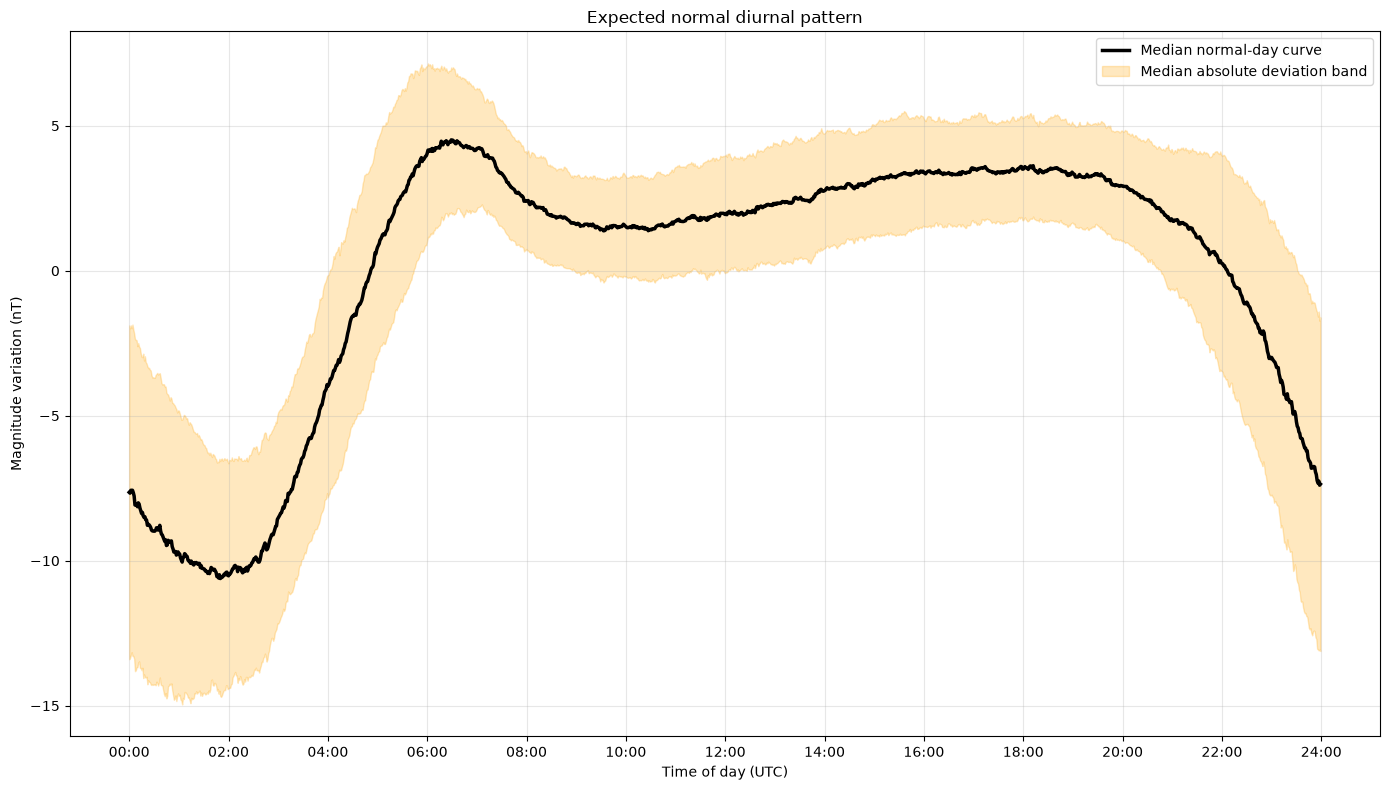

In [136]:
# Analyse the file
res = analyse_file("data/longer-bom.csv", source_tz='UTC')

# Print a summary of the results (optional)
summarise_days(res)

# Plot the normal diurnal curve
fig = plot_normal_curve(res, show_abnormal_days=False, show_normal_days=False)

# Display the plot
plt.show()